In [14]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline


## Example 2: One-Dimensional Problem with Neumann Boundary Conditions

For the classical case $\alpha=1$, the governing equation is

$$
u_t
=
c_d u_{xx}
+
c_su(1-u)(u-a).
$$

The initial condition for Example 2 is

$$
u(x,0)=e^{-(x+1)},
\qquad -1\leq x\leq1.
$$

The boundary conditions are Neumann boundary conditions:

$$
u_x(-1,t)=-1,
$$

and

$$
u_x(1,t)=-\frac{1}{e^2}.
$$




### FTCS Approximation

For the interior grid points, the time derivative is approximated by

$$
u_t(x_i,t_n)
\approx
\frac{u_i^{n+1}-u_i^n}{\Delta t}.
$$

The second spatial derivative is approximated using the centred difference

$$
u_{xx}(x_i,t_n)
\approx
\frac{
u_{i+1}^n-2u_i^n+u_{i-1}^n
}{
(\Delta x)^2
}.
$$

The nonlinear reaction term is evaluated at the current time level:

$$
u(1-u)(u-a)
\approx
u_i^n(1-u_i^n)(u_i^n-a).
$$

Therefore,

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=
c_d
\frac{
u_{i+1}^n-2u_i^n+u_{i-1}^n
}{
(\Delta x)^2
}
+
c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Solving for the new time level gives

$$
\boxed{
u_i^{n+1}
=
u_i^n
+
\frac{c_d\Delta t}{(\Delta x)^2}
\left(
u_{i+1}^n-2u_i^n+u_{i-1}^n
\right)
+
c_s\Delta t\,
u_i^n(1-u_i^n)(u_i^n-a)
}
$$

for

$$
i=1,2,\ldots,N_x-1.
$$


### Neumann Boundary Approximations

At the left boundary, a second-order one-sided approximation is used:

$$
u_x(-1,t)
\approx
\frac{-3u_0+4u_1-u_2}{2\Delta x}.
$$

Using

$$
u_x(-1,t)=-1,
$$

gives

$$
\frac{-3u_0+4u_1-u_2}{2\Delta x}=-1.
$$

Solving for the boundary value gives

$$
\boxed{
u_0
=
\frac{4u_1-u_2+2\Delta x}{3}
}
$$

At the right boundary,

$$
u_x(1,t)
\approx
\frac{3u_N-4u_{N-1}+u_{N-2}}{2\Delta x}.
$$

Using

$$
u_x(1,t)
=
-\frac{1}{e^2},
$$

gives

$$
\boxed{
u_N
=
\frac{
4u_{N-1}-u_{N-2}
-\frac{2\Delta x}{e^2}
}{3}
}
$$

These boundary formulas are applied at every new time level.

In [15]:
def solve_example2_ftcs(
    Nx=80,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    r_target=0.4
):
    # Spatial grid
    x_left = -1.0
    x_right = 1.0

    x = np.linspace(x_left, x_right, Nx + 1)
    dx = x[1] - x[0]

    # Initial condition
    u = np.exp(-(x + 1))

    # FTCS time step
    dt = r_target * dx**2 / cd
    Nt = int(np.ceil(t_final / dt))
    dt = t_final / Nt

    r = cd * dt / dx**2

    # Main midpoint graph uses an even Nx, so x=0 is a grid point
    mid_index = np.argmin(np.abs(x))

    time_values = [0.0]
    midpoint_values = [u[mid_index]]

    # Time loop
    for n in range(Nt):

        u_new = u.copy()

        # Interior points
        for i in range(1, Nx):

            diffusion = (
                r
                * (
                    u[i+1]
                    - 2*u[i]
                    + u[i-1]
                )
            )

            reaction_term = (
                dt
                * cs
                * u[i]
                * (1-u[i])
                * (u[i]-a)
            )

            u_new[i] = (
                u[i]
                + diffusion
                + reaction_term
            )

        # Neumann boundary conditions at the new time level

        # ux(-1,t) = -1
        u_new[0] = (
            4*u_new[1]
            - u_new[2]
            + 2*dx
        ) / 3

        # ux(1,t) = -1/e^2
        u_new[-1] = (
            4*u_new[-2]
            - u_new[-3]
            - 2*dx/np.exp(2)
        ) / 3

        u = u_new

        current_time = (n + 1) * dt
        time_values.append(current_time)
        midpoint_values.append(u[mid_index])

    return (
        x,
        u,
        np.array(time_values),
        np.array(midpoint_values),
        dx,
        dt,
        r
    )


## Main FTCS Solution

In [16]:
x, u, time_values, midpoint_values, dx, dt, r = solve_example2_ftcs(
    Nx=80,
    t_final=0.5
)

mask_01 = time_values <= 0.1 + 1e-12

print("dx =", dx)
print("dt =", dt)
print("r =", r)
print("Starting midpoint =", midpoint_values[0])
print("Midpoint at t = 0.1 =", midpoint_values[mask_01][-1])
print("Final midpoint at t = 0.5 =", midpoint_values[-1])
print("Minimum u at t = 0.5 =", np.min(u))
print("Maximum u at t = 0.5 =", np.max(u))
print("Contains NaN =", np.isnan(u).any())
print("Contains infinity =", np.isinf(u).any())

dx = 0.025000000000000022
dt = 0.00025
r = 0.3999999999999993
Starting midpoint = 0.36787944117144233
Midpoint at t = 0.1 = 0.27377552367674274
Final midpoint at t = 0.5 = 0.2904970127128567
Minimum u at t = 0.5 = -0.021863901357019416
Maximum u at t = 0.5 = 1.1548330060034582
Contains NaN = False
Contains infinity = False


## Midpoint graph u(0,t)

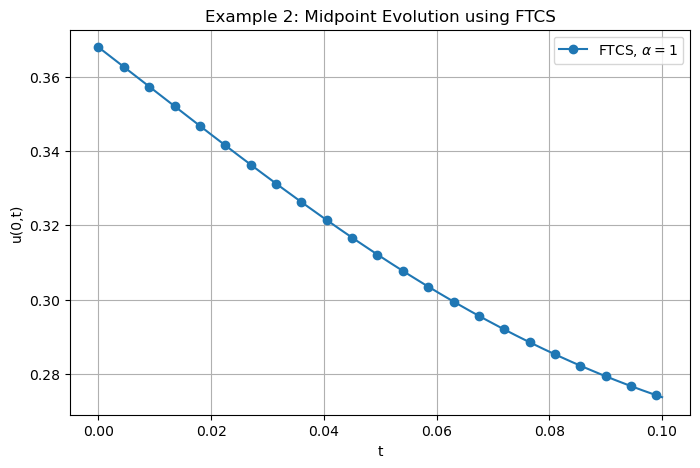

In [17]:
mask_01 = time_values <= 0.1 + 1e-12

plt.figure(figsize=(8, 5))

plt.plot(
    time_values[mask_01],
    midpoint_values[mask_01],
    marker="o",
    markevery=18,
    label=r"FTCS, $\alpha=1$"
)

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 2: Midpoint Evolution using FTCS")
plt.grid(True)
plt.legend()
plt.show()

### Check Neumann Boundary Conditions

In [22]:
left_slope = (
    -3*u[0]
    + 4*u[1]
    - u[2]
) / (2*dx)

right_slope = (
    3*u[-1]
    - 4*u[-2]
    + u[-3]
) / (2*dx)

print("Left boundary slope  =", left_slope)
print("Expected left slope  =", -1.0)

print("Right boundary slope =", right_slope)
print("Expected right slope =", -1/np.exp(2))


Left boundary slope  = -0.9999999999999956
Expected left slope  = -1.0
Right boundary slope = -0.13533528323661256
Expected right slope = -0.1353352832366127


## Mathematica `NDSolve` Reference at \(t=0.5\)

In [23]:
ndsolve_data = pd.read_csv("example2_ndsolve_t05.csv")

required_columns = {"x", "u"}

if not required_columns.issubset(ndsolve_data.columns):
    raise ValueError(
        "The CSV must contain columns named 'x' and 'u'. "
        f"Found columns: {list(ndsolve_data.columns)}"
    )

x_nd = ndsolve_data["x"].to_numpy(dtype=float)
u_nd = ndsolve_data["u"].to_numpy(dtype=float)

sort_index = np.argsort(x_nd)
x_nd = x_nd[sort_index]
u_nd = u_nd[sort_index]

if not np.isfinite(x_nd).all():
    raise ValueError("Invalid x-values were found in the NDSolve reference.")

if not np.isfinite(u_nd).all():
    raise ValueError("Invalid solution values were found in the NDSolve reference.")

ndsolve_interp = CubicSpline(x_nd, u_nd)

print("NDSolve reference loaded successfully.")
print("Number of reference points =", len(x_nd))
print("x-range =", (x_nd[0], x_nd[-1]))
print("Endpoint values =", (u_nd[0], u_nd[-1]))

NDSolve reference loaded successfully.
Number of reference points = 2001
x-range = (np.float64(-1.0), np.float64(1.0))
Endpoint values = (np.float64(1.1550634300677882), np.float64(-0.0217589675328223))


## Maximum Absolute Error

In [24]:
Nx_values = [5, 10, 15, 20, 25, 30]

ftcs_errors = []

print("Nx        Maximum absolute error vs NDSolve")
print("--------------------------------------------")

for Nx in Nx_values:

    (
        x_test,
        u_test,
        _,
        _,
        _,
        _,
        _
    ) = solve_example2_ftcs(
        Nx=Nx,
        cd=1.0,
        cs=50.0,
        a=0.5,
        t_final=0.5,
        r_target=0.4
    )

    # Evaluate Mathematica NDSolve at the same FTCS grid points
    u_nd_at_ftcs = ndsolve_interp(x_test)

    # Maximum absolute error
    max_error = np.max(
        np.abs(
            u_test - u_nd_at_ftcs
        )
    )

    ftcs_errors.append(max_error)

    # Print as ordinary decimals
    print(f"{Nx:<10} {max_error:.10f}")


Nx        Maximum absolute error vs NDSolve
--------------------------------------------
5          0.2339117149
10         0.0668840696
15         0.0325859276
20         0.0191462021
25         0.0123684832
30         0.0084384887


## Discussion of FTCS Results

For Example 2, the FTCS solution was compared with a Mathematica
`NDSolve` reference solution at

$$
t=0.5.
$$

The maximum absolute error was calculated using

$$
E_{\max}
=
\max_i
\left|
u_{\mathrm{FTCS}}(x_i,0.5)
-
u_{\mathrm{NDSolve}}(x_i,0.5)
\right|.
$$

The following results were obtained:

| $N_x$ | Maximum Absolute Error |
|---:|---:|
| 5  | 0.2339117149 |
| 10 | 0.0668840696 |
| 15 | 0.0325859276 |
| 20 | 0.0191462021 |
| 25 | 0.0123684832 |
| 30 | 0.0084384887 |

A clear pattern can be seen in the results: as the grid is refined,
the FTCS solution moves closer to the `NDSolve` reference.

At the coarsest grid,

$$
N_x=5,
$$

the error is relatively large:

$$
0.2339117149.
$$

When the resolution is increased to

$$
N_x=10,
$$

the error drops sharply to

$$
0.0668840696.
$$

The error then continues to decrease for every further increase in
$N_x$.

By

$$
N_x=30,
$$

the maximum absolute error has reduced to

$$
0.0084384887.
$$

This steady decrease is a good indication that the FTCS approximation
is converging towards the Mathematica `NDSolve` solution.

The observed convergence order also improves as the grid becomes finer.
The approximate orders are

$$
1.81,\quad
1.77,\quad
1.85,\quad
1.96,\quad
2.10.
$$

For the finer grids, these values are close to

$$
p=2.
$$

This is consistent with the second-order central finite-difference
approximation used for the spatial derivative.

Example 2 also uses Neumann boundary conditions,

$$
u_x(-1,t)=-1,
$$

and

$$
u_x(1,t)=-e^{-2}.
$$

Unlike Dirichlet conditions, these do not fix the value of the solution
at the endpoints. Instead, they prescribe the slope of the solution.

The numerical boundary checks gave

$$
u_x(-1,t)\approx -1
$$

and

$$
u_x(1,t)\approx -0.1353352832,
$$

which agree extremely closely with the required boundary conditions.

This confirms that the Neumann boundary treatment is working correctly.

Overall, the FTCS results are consistent and show a clear improvement
with grid refinement. The maximum error decreases from approximately
0.234 at $N_x=5$ to approximately 0.0084 at $N_x=30$, while the observed
convergence rate approaches second order on the finer grids.